
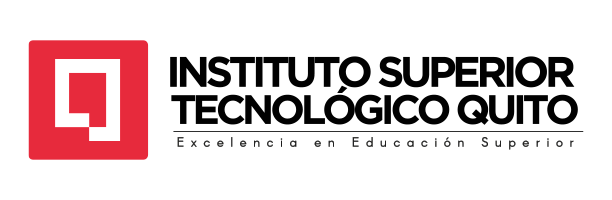

**Nombre**:Elian Suarez

**Fecha**: 9/11/2026

**Link**: <a href="https://github.com/Elits0/Fundamentos_Machine_Learning_26-27">Link repositorio</a>

In [3]:
!pip install -q ucimlrepo

In [4]:
from ucimlrepo import fetch_ucirepo

In [5]:
# Descargar el conjunto de datos desde UCI.
dataset = fetch_ucirepo(id=296)

/usr/local/lib/python3.13/dist-packages/ucimlrepo/fetch.py:97: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


In [6]:
# Obtener una copia de todos los datos.
df = dataset.data.original.copy()

In [7]:
# Verificar que cumple con el tamaño solicitado.
print("Filas y columnas:", df.shape)
assert len(df) > 100_000, "El dataset debe superar los 100 000 registros."


Filas y columnas: (101766, 50)


In [8]:
display(df.head())

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [9]:
# Consultar el diccionario de variables.
display(dataset.variables)


,name,role,type,demographic,description,units,missing_values
0,encounter_id,ID,,None,Unique identifier of an encounter,None,no
1,patient_nbr,ID,,None,Unique identifier of a patient,None,no
2,race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes
3,gender,Feature,Categorical,Gender,"Values: male, female, and unknown/invalid",None,no
4,age,Feature,Categorical,Age,"Grouped in 10-year intervals: [0, 10), [10, 20...",None,no
5,weight,Feature,Categorical,None,Weight in pounds.,None,yes
6,admission_type_id,Feature,Categorical,None,Integer identifier corresponding to 9 distinct...,None,no
7,discharge_disposition_id,Feature,Categorical,None,Integer identifier corresponding to 29 distinc...,None,no
8,admission_source_id,Feature,Categorical,None,Integer identifier corresponding to 21 distinc...,None,no
9,time_in_hospital,Feature,Integer,None,Integer number of days between admission and d...,None,no


In [10]:
# Guardar una copia local para desarrollar la actividad.
df.to_csv("hospitalizaciones_diabetes_original.csv", index=False)

In [11]:
df.describe


<bound method NDFrame.describe of         encounter_id  patient_nbr             race  gender      age weight  \
0            2278392      8222157        Caucasian  Female   [0-10)    NaN   
1             149190     55629189        Caucasian  Female  [10-20)    NaN   
2              64410     86047875  AfricanAmerican  Female  [20-30)    NaN   
3             500364     82442376        Caucasian    Male  [30-40)    NaN   
4              16680     42519267        Caucasian    Male  [40-50)    NaN   
...              ...          ...              ...     ...      ...    ...   
101761     443847548    100162476  AfricanAmerican    Male  [70-80)    NaN   
101762     443847782     74694222  AfricanAmerican  Female  [80-90)    NaN   
101763     443854148     41088789        Caucasian    Male  [70-80)    NaN   
101764     443857166     31693671        Caucasian  Female  [80-90)    NaN   
101765     443867222    175429310        Caucasian    Male  [70-80)    NaN   

        admission_type_id  discharge_disposition_id  admission_source_id  \
0                       6                        25                    1   
1                       1                         1                    7   
2                       1                         1                    7   
3                       1                         1                    7   
4                       1                         1                    7   
...                   ...                       ...                  ...   
101761                  1                         3                    7   
101762                  1                         4                    5   
101763                  1                         1                    7   
101764                  2                         3                    7   
101765                  1                         1                    7   

        time_in_hospital  ... citoglipton insulin  glyburide-metformin  \
0                      1  ...          No      No                   No   
1                      3  ...          No      Up                   No   
2                      2  ...          No      No                   No   
3                      2  ...          No      Up                   No   
4                      1  ...          No  Steady                   No   
...                  ...  ...         ...     ...                  ...   
101761                 3  ...          No    Down                   No   
101762                 5  ...          No  Steady                   No   
101763                 1  ...          No    Down                   No   
101764                10  ...          No      Up                   No   
101765                 6  ...          No      No                   No   

        glipizide-metformin  glimepiride-pioglitazone  \
0                        No                        No   
1                        No                        No   
2                        No                        No   
3                        No                        No   
4                        No                        No   
...                     ...                       ...   
101761                   No                        No   
101762                   No                        No   
101763                   No                        No   
101764                   No                        No   
101765                   No                        No   

        metformin-rosiglitazone  metformin-pioglitazone  change diabetesMed  \
0                            No                      No      No          No   
1                            No                      No      Ch         Yes   
2                            No                      No      No         Yes   
3                            No                      No      Ch         Yes   
4                            No                      No      Ch         Yes   
...                         ...                     ...     ...     

**1. Descripción del problema**

El equipo hospitalario busca analizar cómo se distribuyen las características de las hospitalizaciones de pacientes con diabetes y cómo se relacionan descriptivamente con las readmisiones hospitalarias.

El problema principal consiste en comprender qué características presentan los pacientes hospitalizados, con qué frecuencia regresan al hospital después de recibir el alta médica y qué patrones pueden identificarse en los registros disponibles.

Este análisis es importante porque permite conocer mejor el comportamiento de las hospitalizaciones, identificar posibles factores asociados con las readmisiones y proporcionar información que contribuya a mejorar la atención hospitalaria.

Actores interesados:

Pacientes: buscan recibir una atención adecuada y evitar hospitalizaciones recurrentes.
Médicos: necesitan conocer las características de los pacientes y su evolución hospitalaria.
Hospitales: buscan mejorar la calidad de atención y reducir las readmisiones evitables.
Administradores hospitalarios: necesitan información para planificar recursos y mejorar los servicios de salud.

La exploración de los datos antes de construir modelos es necesaria para conocer la calidad de la información, identificar valores faltantes, detectar registros duplicados, comprender las variables y analizar sus distribuciones.

**2. Objetivo general**

Analizar las características de las hospitalizaciones de pacientes con diabetes registradas en 130 hospitales de Estados Unidos durante el período 1999-2008, mediante técnicas de exploración y análisis descriptivo de datos, con el propósito de identificar patrones en las hospitalizaciones y su relación con las readmisiones hospitalarias.

**3.Identificación de la variable readmitted**
La variable readmitted es una de las más importantes de tu proyecto porque permite analizar si el paciente regresó al hospital.

Valor

Interpretación

NO

El paciente no fue readmitido.

<30

El paciente fue readmitido antes de 30 días.

>30

El paciente fue readmitido después de 30 días.

¿Cómo se utilizará?

Se utilizará como variable de referencia para comparar las características de las hospitalizaciones y observar cómo se distribuyen los registros entre las tres categorías.
Es importante aclarar que en esta fase no se entrenará ningún modelo predictivo.

**5. Limitaciones y consideraciones**

El conjunto de datos utilizado presenta las siguientes limitaciones:

Período de estudio: los registros corresponden a los años 1999-2008, por lo que no necesariamente representan las condiciones actuales de los hospitales.
Población hospitalaria: la información corresponde a pacientes hospitalizados con diabetes en 130 hospitales de Estados Unidos, por lo que los resultados no deben generalizarse a toda la población.
Hospitalizaciones repetidas: un mismo paciente puede aparecer en varios registros debido a diferentes hospitalizaciones. Por esta razón, no se debe asumir que cada fila representa una persona diferente.
Confidencialidad: la información debe analizarse respetando la privacidad de los pacientes. No se debe intentar identificar a ninguna persona.
Alcance del análisis: las relaciones encontradas serán descriptivas y no demostrarán necesariamente causalidad entre las variables y las readmisiones.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
#Se revisa primero las dimensiones
print("Dimensiones:",df.shape)

Dimensiones: (101766, 50)


In [14]:
#Se ve el numero de hospitalizaciones
print("Total de hospitalizaciones:",len(df))

Total de hospitalizaciones: 101766


In [15]:
#Revisamo el numero de paciente unicos de la variable patient_nbr
print("Numero unico de pacientes:", df['patient_nbr'].nunique())

Numero unico de pacientes: 71518


In [16]:
#Revisamos el numero de registros de cada paciente
print("Pacientes con hospitalizaciones repetidas:",
      df['patient_nbr'].duplicated().sum())

Pacientes con hospitalizaciones repetidas: 30248


**Estos pacientes con hospitalizaciones repetidas, seran un dato importante para saber si un paciente puede llegar a tener una rehospitalizacion, ya que depende de la sintomatologia, y si esta sintomatoliga se llega a repetir, pues puede ser una buena señal de aventencia para otro paciente**

In [17]:
#Revisamos los primeros registros de dataset// lo que ya hicimos arriba pero para no estar sube y baja lo vuevlo a hacer aqui xddd
display(df.head())

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [18]:
#Hago el rpiemr inventario de columnas, para empezar con el analisis de estos datos
diccionario = pd.DataFrame({
    'Variable': df.columns,
    'Tipo observado': df.dtypes.astype(str).values,
    'Valores únicos': df.nunique().values,
    'Valores faltantes': df.isnull().sum().values
})

display(diccionario)

,Variable,Tipo observado,Valores únicos,Valores faltantes
0,encounter_id,int64,101766,0
1,patient_nbr,int64,71518,0
2,race,object,5,2273
3,gender,object,3,0
4,age,object,10,0
5,weight,object,9,98569
6,admission_type_id,int64,8,0
7,discharge_disposition_id,int64,26,0
8,admission_source_id,int64,17,0
9,time_in_hospital,int64,14,0


In [19]:
#Reviso los valroes flatantes, a ver klk
print("Valores nulos:")
print(df.isnull().sum().sort_values(ascending=False).head(20))

#Revisar el marcador ?, para ver valores que falten o no se hayan guardado de manera correcta
print("Valores con ?:")
print((df.astype(str) == '?').sum().sort_values(ascending=False).head(20))

#Revisar si existen valores None como categoría
for col in df.select_dtypes(include='object').columns:
    if 'None' in df[col].astype(str).values:
        print(col, "contiene la categoría None")

Valores nulos:
weight                      98569
max_glu_serum               96420
A1Cresult                   84748
medical_specialty           49949
payer_code                  40256
race                         2273
diag_3                       1423
diag_2                        358
diag_1                         21
patient_nbr                     0
time_in_hospital                0
admission_source_id             0
num_lab_procedures              0
encounter_id                    0
admission_type_id               0
discharge_disposition_id        0
gender                          0
age                             0
number_inpatient                0
number_emergency                0
dtype: int64
Valores con ?:
encounter_id                0
patient_nbr                 0
race                        0
gender                      0
age                         0
weight                      0
admission_type_id           0
discharge_disposition_id    0
admission_source_id         0
time_in

**Variables con valroes nuelos**:

weight                      98569

max_glu_serum               96420

A1Cresult                   84748

medical_specialty           49949

payer_code                  40256

race                         2273

diag_3                       1423

diag_2                        358

diag_1                         21

**No tenemos ningun valor con '?'**


In [20]:
#Construyo tabla con valores faltantes
#Primera copia de trabajo
df_limpio = df.copy()

#Tabla de valroes faltantes
faltantes = pd.DataFrame({
    'Cantidad': df_limpio.isnull().sum(),
    'Porcentaje': df_limpio.isnull().mean() * 100
})

faltantes = faltantes.sort_values(
    by='Porcentaje',
    ascending=False
)

display(faltantes)

,Cantidad,Porcentaje
weight,98569,96.858479
max_glu_serum,96420,94.746772
A1Cresult,84748,83.277322
medical_specialty,49949,49.082208
payer_code,40256,39.557416
race,2273,2.233555
diag_3,1423,1.398306
diag_2,358,0.351787
diag_1,21,0.020636
patient_nbr,0,0.000000


In [21]:
#Revision por si hay datos duplicados
duplicados = df_limpio.duplicated().sum()
print("Filas duplicadas:", duplicados)

#Identificadores de hospitalización repetidos
print("Encounter ID repetidos:",
      df_limpio['encounter_id'].duplicated().sum())

#Identificadores de pacientes repetidos
print("Patient NBR repetidos:",
      df_limpio['patient_nbr'].duplicated().sum())

#Pacientes con más de una hospitalización
hospitalizaciones = df_limpio.groupby(
    'patient_nbr'
).size()
print("Pacientes con varias hospitalizaciones:",
      (hospitalizaciones > 1).sum())

Filas duplicadas: 0
Encounter ID repetidos: 0
Patient NBR repetidos: 30248
Pacientes con varias hospitalizaciones: 16773


In [22]:
#Selecciono variables solo numericas
columnas_numericas = df_limpio.select_dtypes(
    include=np.number
).columns.tolist()

#Separo los identifcadores
columnas_numericas = [
    col for col in columnas_numericas
    if col not in ['encounter_id', 'patient_nbr']
]

estadisticas = df_limpio[columnas_numericas].describe().T

estadisticas['mediana'] = df_limpio[
    columnas_numericas
].median()

display(estadisticas)

,count,mean,std,min,25%,50%,75%,max,mediana
admission_type_id,101766.0,2.024006,1.445403,1.0,1.0,1.0,3.0,8.0,1.0
discharge_disposition_id,101766.0,3.715642,5.280166,1.0,1.0,1.0,4.0,28.0,1.0
admission_source_id,101766.0,5.754437,4.064081,1.0,1.0,7.0,7.0,25.0,7.0
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0,4.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0,44.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0,1.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0,15.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0,0.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0,0.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0,0.0


Mínimo: menor cantidad de días de hospitalización.

Máximo: mayor cantidad de días.

Media: promedio de días hospitalizados.

Mediana: valor central de los días.

Desviación estándar: cuánto varían los días respecto al promedio.

Cuartiles: permiten observar cómo se distribuyen los días de hospitalización.

In [23]:
#Frecuencias de el readmited
frecuencias = df_limpio['readmitted'].value_counts()
#porcentajes
porcentajes =df_limpio['readmitted'].value_counts(normalize=True)*100
tabla_readmitted = pd.DataFrame({
    'Frecuencia': frecuencias,
    'Porcentaje': porcentajes
})
display(tabla_readmitted)

,Frecuencia,Porcentaje
readmitted,,
NO,54864,53.911916
>30,35545,34.928169
<30,11357,11.159916


NO: pacientes que no fueron readmitidos.

<30: pacientes readmitidos antes de 30 días.

>30: pacientes readmitidos después de 30 días.

**HISTOGRAMA DE HOSPITALIZACIONES**

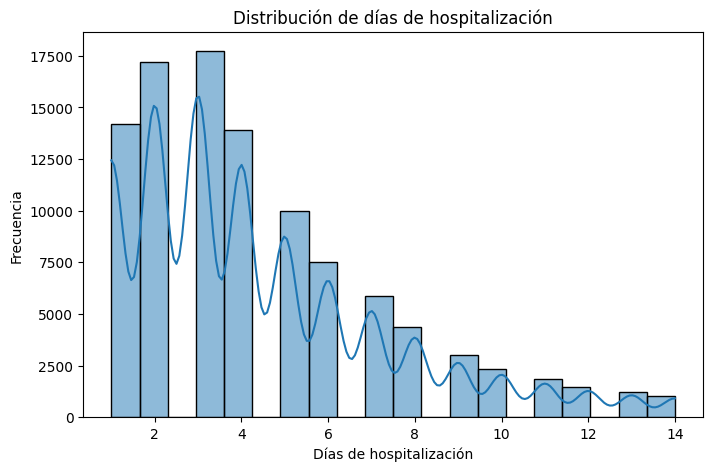

In [24]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df_limpio,
    x='time_in_hospital',
    bins=20,
    kde=True
)

plt.title('Distribución de días de hospitalización')
plt.xlabel('Días de hospitalización')
plt.ylabel('Frecuencia')

plt.show()

**DIAGRAMA DE CAJA DE HOSPITALIZACIONES**

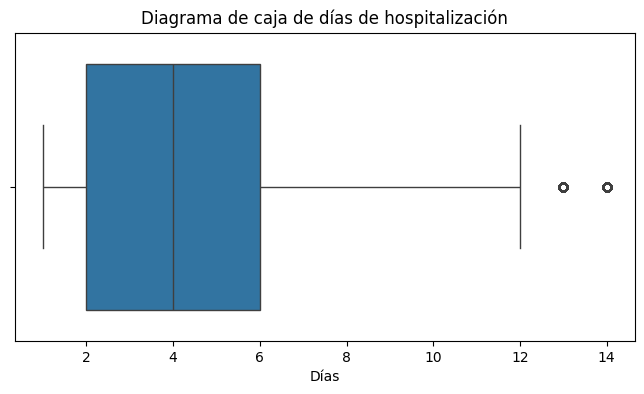

In [25]:
plt.figure(figsize=(8,4))

sns.boxplot(
    data=df_limpio,
    x='time_in_hospital'
)

plt.title('Diagrama de caja de días de hospitalización')
plt.xlabel('Días')

plt.show()

**HISTOGRAMA DE MEDICAMENTOS**

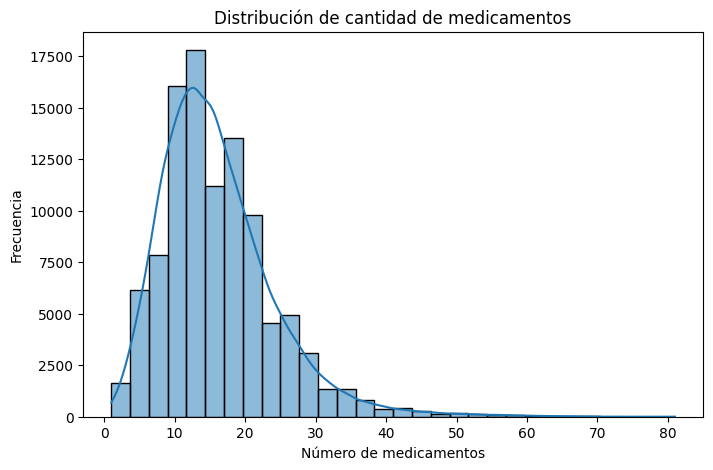

In [26]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df_limpio,
    x='num_medications',
    bins=30,
    kde=True
)

plt.title('Distribución de cantidad de medicamentos')
plt.xlabel('Número de medicamentos')
plt.ylabel('Frecuencia')

plt.show()

**DIAGRAMA DE CAJA DE MEDICAMENTOS**

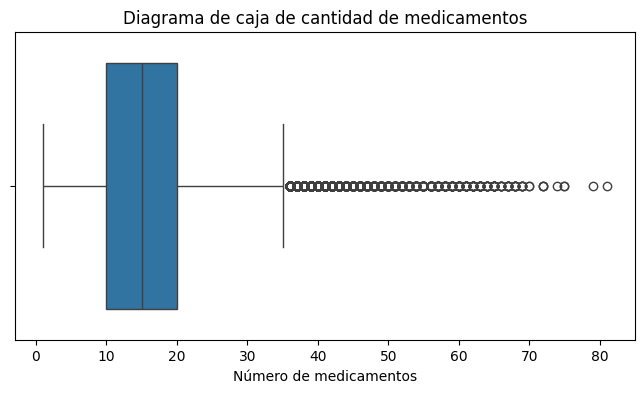

In [27]:
plt.figure(figsize=(8,4))

sns.boxplot(
    data=df_limpio,
    x='num_medications'
)

plt.title('Diagrama de caja de cantidad de medicamentos')
plt.xlabel('Número de medicamentos')

plt.show()

**FRECUENCIAS DE READMITTED**

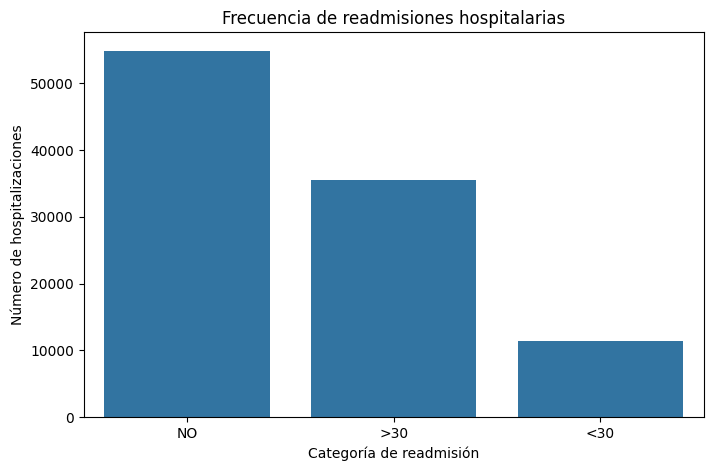

In [28]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df_limpio,
    x='readmitted',
    order=['NO', '>30', '<30']
)

plt.title('Frecuencia de readmisiones hospitalarias')
plt.xlabel('Categoría de readmisión')
plt.ylabel('Número de hospitalizaciones')

plt.show()

**NORMALIZACION**

In [29]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd
import numpy as np

In [30]:
columnas_numericas = [
    'time_in_hospital',
    'num_lab_procedures',
    'num_procedures',
    'num_medications',
    'number_outpatient',
    'number_emergency',
    'number_inpatient'
]
#Crear una copia sin modificar el dataset original
df_numerico = df[columnas_numericas].copy()
#Verificar dimensiones y primeras filas
print("Dimensiones:", df_numerico.shape)
display(df_numerico.head(10))

Dimensiones: (101766, 7)


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,1,41,0,1,0,0,0
1,3,59,0,18,0,0,0
2,2,11,5,13,2,0,1
3,2,44,1,16,0,0,0
4,1,51,0,8,0,0,0
5,3,31,6,16,0,0,0
6,4,70,1,21,0,0,0
7,5,73,0,12,0,0,0
8,13,68,2,28,0,0,0
9,12,33,3,18,0,0,0


In [31]:
#Convertir las columnas a valores numéricos
df_numerico = df_numerico.apply(
    pd.to_numeric, errors='coerce'
)
#Verificar valores faltantes
print("Valores faltantes por columna:")
print(df_numerico.isnull().sum())
#Conservar los datos completos para la normalización
assert df_numerico.notna().all().all(), \
    "Existen valores faltantes que deben tratarse antes de normalizar."

print("Datos listos para normalizar.")

Valores faltantes por columna:
time_in_hospital      0
num_lab_procedures    0
num_procedures        0
num_medications       0
number_outpatient     0
number_emergency      0
number_inpatient      0
dtype: int64
Datos listos para normalizar.


In [32]:
# Convertir las columnas a valores numéricos
df_numerico = df_numerico.apply(
    pd.to_numeric, errors='coerce'
)
# Verificar valores faltantes
print("Valores faltantes por columna:")
print(df_numerico.isnull().sum())
# Conservar los datos completos para la normalización
assert df_numerico.notna().all().all(), \
    "Existen valores faltantes que deben tratarse antes de normalizar."
print("Datos listos para normalizar.")

Valores faltantes por columna:
time_in_hospital      0
num_lab_procedures    0
num_procedures        0
num_medications       0
number_outpatient     0
number_emergency      0
number_inpatient      0
dtype: int64
Datos listos para normalizar.


In [33]:
#Crear el normalizador
normalizador = MinMaxScaler(feature_range=(0, 1))
#Aplicar normalización
datos_normalizados = normalizador.fit_transform(df_numerico)
#Convertir el resultado a DataFrame
df_normalizado = pd.DataFrame(
    datos_normalizados,
    columns=columnas_numericas,
    index=df_numerico.index
)
Mostrar las primeras 10 filas
print("DATOS NORMALIZADOS")
display(df_normalizado.head(10))

DATOS NORMALIZADOS


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,0.000000,0.305344,0.000000,0.0000,0.000000,0.0,0.000000
1,0.153846,0.442748,0.000000,0.2125,0.000000,0.0,0.000000
2,0.076923,0.076336,0.833333,0.1500,0.047619,0.0,0.047619
3,0.076923,0.328244,0.166667,0.1875,0.000000,0.0,0.000000
4,0.000000,0.381679,0.000000,0.0875,0.000000,0.0,0.000000
5,0.153846,0.229008,1.000000,0.1875,0.000000,0.0,0.000000
6,0.230769,0.526718,0.166667,0.2500,0.000000,0.0,0.000000
7,0.307692,0.549618,0.000000,0.1375,0.000000,0.0,0.000000
8,0.923077,0.511450,0.333333,0.3375,0.000000,0.0,0.000000
9,0.846154,0.244275,0.500000,0.2125,0.000000,0.0,0.000000


In [34]:
comparacion = pd.DataFrame({
    'Min Original': df_numerico.min(),
    'Max Original': df_numerico.max(),
    'Min Normalizado': df_normalizado.min(),
    'Max Normalizado': df_normalizado.max()
})

print("COMPARACIÓN ANTES Y DESPUÉS")
display(comparacion)

COMPARACIÓN ANTES Y DESPUÉS


,Min Original,Max Original,Min Normalizado,Max Normalizado
time_in_hospital,1,14,0.0,1.0
num_lab_procedures,1,132,0.0,1.0
num_procedures,0,6,0.0,1.0
num_medications,1,81,0.0,1.0
number_outpatient,0,42,0.0,1.0
number_emergency,0,76,0.0,1.0
number_inpatient,0,21,0.0,1.0


In [35]:
#Comprobar que todos los valores estén entre 0 y 1
tolerancia = 1e-9
assert (
    (df_normalizado >= -tolerancia) &
    (df_normalizado <= 1 + tolerancia)
).all().all(), "Error: existen valores fuera del rango."
assert df_normalizado.shape == df_numerico.shape, \
    "Las dimensiones cambiaron."
print("Normalización realizada correctamente.")
print("Todos los valores están entre 0 y 1.")
print("Registros normalizados:", len(df_normalizado))

Normalización realizada correctamente.
Todos los valores están entre 0 y 1.
Registros normalizados: 101766


In [36]:
df_normalizado.to_csv(
    "datos_normalizados.csv",
    index=False
)

print("Archivo datos_normalizados.csv guardado correctamente.")

Archivo datos_normalizados.csv guardado correctamente.


### Interpretación de la normalización Min-Max

Se aplicó la técnica de normalización Min-Max a siete variables cuantitativas del conjunto de datos de hospitalizaciones de pacientes con diabetes.

Esta transformación permite convertir los valores originales a una escala comprendida entre 0 y 1, conservando las proporciones relativas entre los valores de cada variable.

El procedimiento se realizó mediante la herramienta `MinMaxScaler` de la biblioteca `scikit-learn`, sin modificar los registros originales.

La normalización facilita la comparación de variables que inicialmente presentan diferentes rangos de valores. Sin embargo, no elimina los valores atípicos ni modifica la forma general de las distribuciones.

**Estandarizacion**

In [37]:
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

In [38]:
columnas_numericas = [
    'time_in_hospital',
    'num_lab_procedures',
    'num_procedures',
    'num_medications',
    'number_outpatient',
    'number_emergency',
    'number_inpatient'
]

# Obtener los datos numéricos originales
df_numerico = df[columnas_numericas].copy()

# Convertir a valores numéricos
df_numerico = df_numerico.apply(
    pd.to_numeric, errors='coerce'
)

# Verificar valores faltantes
assert df_numerico.notna().all().all(), \
    "Existen valores faltantes que deben tratarse."

print("Datos originales preparados")
display(df_numerico.head(10))

Datos originales preparados


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,1,41,0,1,0,0,0
1,3,59,0,18,0,0,0
2,2,11,5,13,2,0,1
3,2,44,1,16,0,0,0
4,1,51,0,8,0,0,0
5,3,31,6,16,0,0,0
6,4,70,1,21,0,0,0
7,5,73,0,12,0,0,0
8,13,68,2,28,0,0,0
9,12,33,3,18,0,0,0


In [39]:
# Crear el estandarizador
estandarizador = StandardScaler()
# Aplicar estandarización sobre datos originales
datos_estandarizados = estandarizador.fit_transform(df_numerico)
# Convertir resultado a DataFrame
df_estandarizado = pd.DataFrame(
    datos_estandarizados,
    columns=columnas_numericas,
    index=df_numerico.index
)
print("DATOS ESTANDARIZADOS")
display(df_estandarizado.head(10))

DATOS ESTANDARIZADOS


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,-1.137649,-0.106517,-0.785398,-1.848268,-0.291461,-0.21262,-0.503276
1,-0.467653,0.808384,-0.785398,0.243390,-0.291461,-0.21262,-0.503276
2,-0.802651,-1.631351,2.145781,-0.371804,1.286748,-0.21262,0.288579
3,-0.802651,0.045967,-0.199162,-0.002688,-0.291461,-0.21262,-0.503276
4,-1.137649,0.401761,-0.785398,-0.986997,-0.291461,-0.21262,-0.503276
5,-0.467653,-0.614795,2.732016,-0.002688,-0.291461,-0.21262,-0.503276
6,-0.132655,1.367490,-0.199162,0.612506,-0.291461,-0.21262,-0.503276
7,0.202343,1.519973,-0.785398,-0.494842,-0.291461,-0.21262,-0.503276
8,2.882327,1.265834,0.387074,1.473776,-0.291461,-0.21262,-0.503276
9,2.547329,-0.513139,0.973309,0.243390,-0.291461,-0.21262,-0.503276


In [40]:
comparacion_estandarizacion = pd.DataFrame({
    'Media Original': df_numerico.mean(),
    'Desviación Original': df_numerico.std(ddof=0),
    'Media Estandarizada': df_estandarizado.mean(),
    'Desviación Estandarizada': df_estandarizado.std(ddof=0)
})

print("COMPARACIÓN ANTES Y DESPUÉS")
display(comparacion_estandarizacion)

COMPARACIÓN ANTES Y DESPUÉS


,Media Original,Desviación Original,Media Estandarizada,Desviación Estandarizada
time_in_hospital,4.395987,2.985093,5.809126e-17,1.0
num_lab_procedures,43.095641,19.674266,1.161825e-16,1.0
num_procedures,1.339730,1.705799,-6.479410e-17,1.0
num_medications,16.021844,8.127526,-1.340568e-16,1.0
number_outpatient,0.369357,1.267259,3.574847e-17,1.0
number_emergency,0.197836,0.930468,1.787424e-17,1.0
number_inpatient,0.635566,1.262857,-3.574847e-17,1.0


In [41]:
# Verificar media aproximadamente 0
medias = df_estandarizado.mean()
# Verificar desviación estándar aproximadamente 1
desviaciones = df_estandarizado.std(ddof=0)
# Identificar columnas constantes
columnas_constantes = df_numerico.nunique() <= 1
assert np.allclose(medias, 0, atol=1e-9), \
    "Error: las medias no son aproximadamente 0."
assert np.allclose(
    desviaciones[~columnas_constantes], 1, atol=1e-9
), "Error: la desviación estándar no es aproximadamente 1."
assert np.allclose(
    desviaciones[columnas_constantes], 0, atol=1e-9
), "Error en las columnas constantes."
print("Estandarización realizada correctamente.")
print("Medias aproximadamente iguales a 0.")
print("Desviaciones estándar iguales a 1 en variables no constantes.")
print("Registros estandarizados:", len(df_estandarizado))

Estandarización realizada correctamente.
Medias aproximadamente iguales a 0.
Desviaciones estándar iguales a 1 en variables no constantes.
Registros estandarizados: 101766


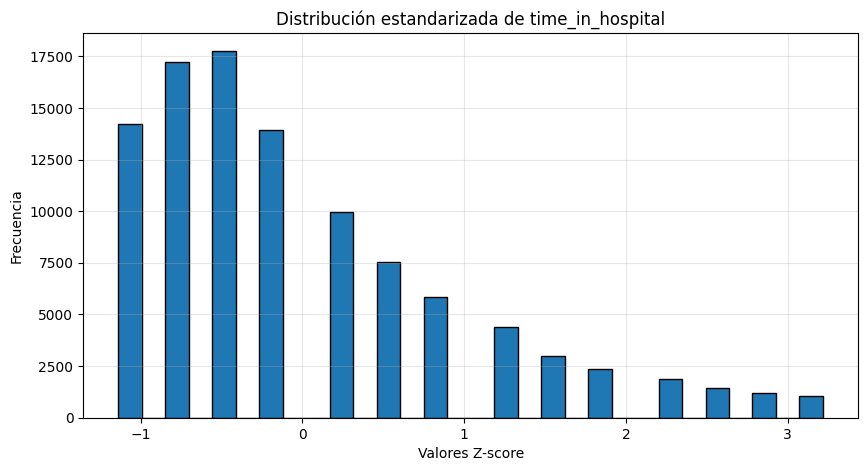

In [42]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.hist(
    df_estandarizado['time_in_hospital'],
    bins=30,
    edgecolor='black'
)
plt.title('Distribución estandarizada de time_in_hospital')
plt.xlabel('Valores Z-score')
plt.ylabel('Frecuencia')

plt.grid(alpha=0.3)
plt.show()

In [43]:
df_estandarizado.to_csv(
    "datos_estandarizados.csv",
    index=False
)

print("Archivo datos_estandarizados.csv guardado correctamente.")

Archivo datos_estandarizados.csv guardado correctamente.


### Interpretación de la estandarización Z-score

Se aplicó la técnica de estandarización Z-score mediante `StandardScaler` a las siete variables cuantitativas del conjunto de datos de hospitalizaciones de pacientes con diabetes.

Este procedimiento transforma los datos para obtener una media aproximadamente igual a 0 y una desviación estándar igual a 1 en las variables no constantes.

A diferencia de la normalización Min-Max, los valores estandarizados pueden ser negativos, positivos o superiores a 1, ya que representan la distancia de cada observación respecto a la media, medida en desviaciones estándar.

La estandarización permite comparar variables con diferentes unidades y escalas, conservando la forma general de sus distribuciones. Sin embargo, no elimina los valores atípicos ni garantiza una distribución normal.